# Introduction to terms

A term is one part of a model.
Start with a saturation curve:

```text
Y ~ saturation(X)
```

More spend increases the mean response.
The increase becomes smaller as spend increases.
Make this model with PyMC, components, and terms.
Then add an intercept, price, and two operating system (OS) outcomes.

Run the cells in order.
This notebook uses prior predictions only.
It does not fit a model or optimize a plan.

**Warning:** The API in `pymc_marketing.experimental.terms` is experimental and can change.
Its implementation is in [PR #2981](https://github.com/pymc-labs/pymc-marketing/pull/2981).
For more component examples, see [Custom models with MMM components](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_components.html).

## 1. Make a small labeled dataset

Use two media channels and one observed response per week.
The simulated values are already on a small scale.
Terms do not scale data automatically.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

rng = np.random.default_rng(42)

Simulate spend for 52 weeks.
Use the same saturation curve for the two channels.
Add Normal noise to the total response.

In [2]:
spend = rng.uniform(0, 1, size=(52, 2))
response = (1.2 * np.tanh(3 * spend / 2)).sum(axis=1)
target = response + rng.normal(0, 0.08, size=52)

Put the values in one `xarray.Dataset`.
Each variable is a named `DataArray`.
`X` has dimensions `date` and `channel`; `Y` has dimension `date`.

In [3]:
train = xr.Dataset(
    {"X": (("date", "channel"), spend), "Y": ("date", target)},
    coords={
        "date": pd.date_range("2025-01-06", periods=52, freq="W-MON"),
        "channel": ["tv", "search"],
    },
)
train

<xarray.Dataset> Size: 2kB
Dimensions:  (date: 52, channel: 2)
Coordinates:
  * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
  * channel  (channel) <U6 48B 'tv' 'search'
Data variables:
    X        (date, channel) float64 832B 0.774 0.4389 0.8586 ... 0.2659 0.9692
    Y        (date) float64 416B 1.65 2.026 1.172 1.954 ... 1.2 1.856 1.492

Plot channel spend `X` and the observed response `Y` before you build the model.

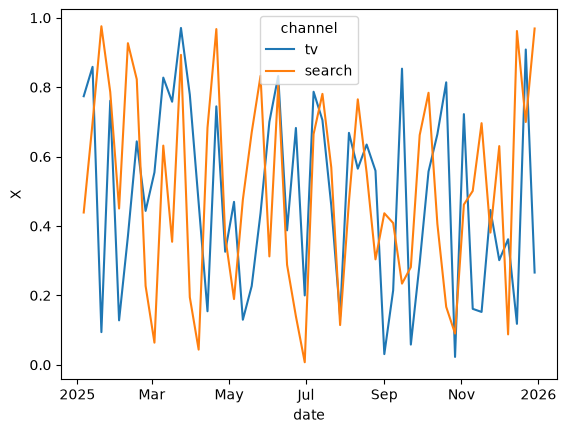

In [4]:
train["X"].plot.line(x="date", hue="channel");

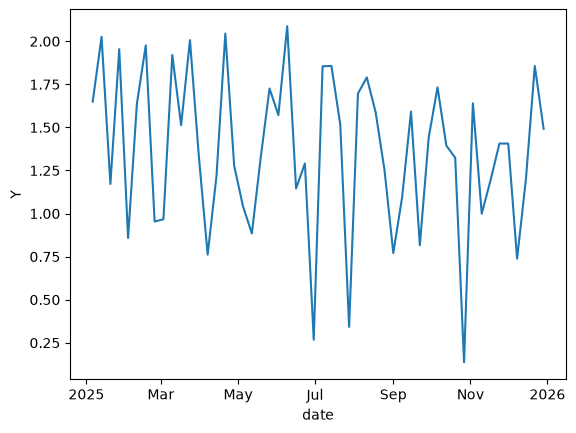

In [5]:
train["Y"].plot.line(x="date");

## 2. Build it with PyMC only

Use this logistic saturation curve for each channel:

$$f(X_c) = \beta_c\tanh(\lambda_c X_c / 2).$$

The parameter $\beta_c$ sets the maximum response.
The parameter $\lambda_c$ sets the curve shape.
Add the channel responses to get the mean of `Y`.
Use a Normal likelihood for observation noise.
This model has no intercept or adstock.

In [6]:
import pymc as pm

coords = {dim: train.coords[dim].values for dim in train.dims}

Make the input and the two parameter priors in a PyMC model context.
Then calculate the channel responses.
The `channel` axis is last, so `axis=-1` selects it.

In [7]:
with pm.Model(coords=coords) as pymc_model:
    x = pm.Data("X", train["X"].values, dims=("date", "channel"))
    lam = pm.Gamma("saturation_lam", alpha=3, beta=1, dims="channel")
    beta = pm.HalfNormal("saturation_beta", sigma=2, dims="channel")
    channel_response = beta * pm.math.tanh(lam * x / 2)

Add the observation model.
Open the same model context again to keep this step separate.

In [8]:
with pymc_model:
    sigma = pm.HalfNormal("Y_sigma", sigma=2)
    pm.Normal(
        "Y",
        mu=channel_response.sum(axis=-1),
        sigma=sigma,
        observed=train["Y"].values,
        dims="date",
    )

Show the PyMC graph with its likelihood.

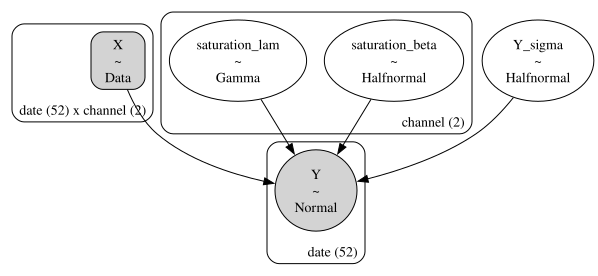

In [9]:
pm.model_to_graphviz(pymc_model)

## 3. Let a component supply the saturation

`LogisticSaturation` supplies the curve and its default priors.
Make the model context, input, and likelihood.

Components use `pymc.dims` to align tensors by dimension name.
Thus, an axis position is not necessary.

In [10]:
import pymc.dims as pmd

from pymc_marketing.mmm import LogisticSaturation

component = LogisticSaturation().with_default_prior_dims(("channel",))

Set the prior dimensions to `channel`.
Each channel then has its own saturation parameters.
Show the priors to see these dimensions.
The priors match the Gamma and HalfNormal distributions above.

In [11]:
component.function_priors

{'lam': Prior("Gamma", alpha=3, beta=1, dims="channel"),
 'beta': Prior("HalfNormal", sigma=2, dims="channel")}

In [12]:
with pm.Model(coords=coords) as component_model:
    x = pmd.Data("X", train["X"], dims=("date", "channel"))
    channel_response = component.apply(x, core_dim="date")

Add the same noise model.
Sum over the named `channel` dimension.

In [13]:
with component_model:
    sigma = pmd.HalfNormal("Y_sigma", sigma=2)
    pmd.Normal(
        "Y",
        mu=channel_response.sum("channel"),
        sigma=sigma,
        observed=train["Y"],
        dims="date",
    )

## 4. Write the model with terms

`Data("X")` refers to the dataset variable `X`.
It does not contain the training values.
The operator `>>` applies a transformation to a term.

In [14]:
from pymc_marketing.experimental.terms import GAM, Data, Equation

X = Data("X")
saturation = LogisticSaturation()

Use these parts to define the model in one line.

In [15]:
gam = GAM(Equation(observed="Y", mu=(X >> saturation).sum("channel")))

Read the parts in order:

- `X >> saturation` applies the curve to each channel.
- `.sum("channel")` adds the channel responses, not the dates.
- `Equation` connects the mean to the observed variable `Y`.
- `GAM` builds and manages the model.

`Equation` uses a Normal likelihood by default.
Its shared noise prior is `HalfNormal(sigma=2)`.
The saturation component also supplies default priors.
The priors are present even when you do not configure them.

This is the same statistical model as the two versions above.
No model context or custom model class is necessary.

The definition does not make PyMC variables.
Supply the dataset to make these variables.

In [16]:
gam.build_model(train);

Show the model table.
The two saturation parameters have dimension `channel`.
The observation `Y` has dimension `date`.
The input name `X` matches the dataset variable.

In [17]:
from pymc_extras.printing import model_table

model_table(gam.model)

          Variable  Expression                                           Dimensions            
───────────────────────────────────────────────────────────────────────────────────────────────
               X =  Data                                                 date[52] × channel[2] 
                                                                                               
  saturation_lam ~  Gamma(3, <constant>)                                 channel[2]            
 saturation_beta ~  HalfNormal(0, 2)                                     channel[2]            
         Y_sigma ~  HalfNormal(0, 2)                                                           
                                                                         Parameter count = 5   
                                                                                               
               Y ~  Normal(f(saturation_beta, saturation_lam), Y_sigma)  date[52]

### Match the data names

Supply training data as an `xarray.Dataset`.
Do not supply a NumPy array, DataFrame, or separate `DataArray`.

- `Data("X")` reads `train["X"]`.
- `observed="Y"` reads `train["Y"]`.
- Match the spelling and case of each variable name.
- Use unique coordinate labels with no missing values.
- Put dates in increasing order.

`date` and `channel` are dimension names.
The Python variable `train` can have a different name.
Only the names inside the dataset connect data to terms.
The model states which dimensions to sum.

In [18]:
train["X"].dims, train["Y"].dims

(('date', 'channel'), ('date',))

## 5. Select which parameters are shared

Data dimensions and parameter dimensions are separate choices.
For example, two channels can share one saturation curve.

Select the prior dimensions:

| Prior setting | Parameters for `X(date, channel)` |
| --- | --- |
| Omitted `dims` (`None`) | Infer one parameter per channel. |
| `dims="channel"` | Set one parameter per channel explicitly. |
| `dims=()` | Use one scalar parameter for all channels. |

Omitted dimensions are not the same as `dims=()`.
Separate channel parameters do not give partial pooling.
Use a hierarchical prior for partial pooling.

Use `with_default_prior_dims` to set dimensions for the two default priors.
It returns a copy.
It keeps dimensions that are already set.

In [19]:
by_channel = LogisticSaturation().with_default_prior_dims(("channel",))
by_channel.function_priors

{'lam': Prior("Gamma", alpha=3, beta=1, dims="channel"),
 'beta': Prior("HalfNormal", sigma=2, dims="channel")}

Use scalar dimensions for complete pooling across channels.
This sets `dims=()` for the two default priors.

In [20]:
fully_pooled = LogisticSaturation().with_default_prior_dims(())
fully_pooled.function_priors

{'lam': Prior("Gamma", alpha=3, beta=1, dims=()),
 'beta': Prior("HalfNormal", sigma=2, dims=())}

Build the pooled model with the same data.
Only the saturation configuration changes.
Keep the sum over channels.

In [21]:
pooled_response = (X >> fully_pooled).sum("channel")
pooled_gam = GAM(Equation(observed="Y", mu=pooled_response))
pooled_gam.build_model(train)
model_table(pooled_gam.model)

          Variable  Expression                                           Dimensions            
───────────────────────────────────────────────────────────────────────────────────────────────
               X =  Data                                                 date[52] × channel[2] 
                                                                                               
  saturation_lam ~  Gamma(3, <constant>)                                                       
 saturation_beta ~  HalfNormal(0, 2)                                                           
         Y_sigma ~  HalfNormal(0, 2)                                                           
                                                                         Parameter count = 3   
                                                                                               
               Y ~  Normal(f(saturation_beta, saturation_lam), Y_sigma)  date[52]

The two saturation parameters are scalars.
Each channel uses the same parameter values.
Separate parameters with the same prior would not give complete pooling.

## 6. Add a geographic dimension in the data

Add a second market with 30% more spend.
Use the dimension `geo` to label the markets.

In [22]:
geo_spend = xr.concat(
    [train["X"], 1.3 * train["X"]],
    dim=xr.IndexVariable("geo", ["north", "south"]),
)

Simulate a separate observation for each market and week.
`X` has dimensions `geo`, `date`, and `channel`.
`Y` has dimensions `geo` and `date`.
Keep the xarray dimension order; terms use dimension names.

In [23]:
geo_mean = (1.2 * np.tanh(3 * geo_spend / 2)).sum("channel")
geo_train = xr.Dataset(
    {
        "X": geo_spend,
        "Y": geo_mean + rng.normal(0, 0.08, size=geo_mean.shape),
    }
)
geo_train

<xarray.Dataset> Size: 3kB
Dimensions:  (date: 52, channel: 2, geo: 2)
Coordinates:
  * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
  * channel  (channel) <U6 48B 'tv' 'search'
  * geo      (geo) <U5 40B 'north' 'south'
Data variables:
    X        (geo, date, channel) float64 2kB 0.774 0.4389 ... 0.3456 1.26
    Y        (geo, date) float64 832B 1.674 2.108 1.257 ... 1.478 2.22 1.688

Build the same specification from section 4 with the new dataset.
`build_model` makes a new PyMC model.

In [24]:
gam.build_model(geo_train)
model_table(gam.model)

          Variable  Expression                                           Dimensions                     
────────────────────────────────────────────────────────────────────────────────────────────────────────
               X =  Data                                                 geo[2] × date[52] × channel[2] 
                                                                                                        
  saturation_lam ~  Gamma(3, <constant>)                                 geo[2] × channel[2]            
 saturation_beta ~  HalfNormal(0, 2)                                     geo[2] × channel[2]            
         Y_sigma ~  HalfNormal(0, 2)                                                                    
                                                                         Parameter count = 9            
                                                                                                        
               Y ~  Normal(f(saturation_beta, saturation_lam), Y_sigma)  geo[2] × date[52]

The default saturation priors have dimensions `geo` and `channel`.
These are the input dimensions other than `date`.
The observations keep the dimensions of `geo_train["Y"]`.
The channel sum gives one mean per market and date.

An explicit scalar or channel-only prior keeps its dimensions.
Use `by_channel` to share each channel curve across markets.

In [25]:
geo_response = (X >> by_channel).sum("channel")
geo_shared_gam = GAM(Equation(observed="Y", mu=geo_response))
geo_shared_gam.build_model(geo_train)
model_table(geo_shared_gam.model)

          Variable  Expression                                           Dimensions                     
────────────────────────────────────────────────────────────────────────────────────────────────────────
               X =  Data                                                 geo[2] × date[52] × channel[2] 
                                                                                                        
  saturation_lam ~  Gamma(3, <constant>)                                 channel[2]                     
 saturation_beta ~  HalfNormal(0, 2)                                     channel[2]                     
         Y_sigma ~  HalfNormal(0, 2)                                                                    
                                                                         Parameter count = 5            
                                                                                                        
               Y ~  Normal(f(saturation_beta, saturation_lam), Y_sigma)  geo[2] × date[52]

The saturation parameters have only dimension `channel` again.
The response has dimensions `geo` and `date`.
Use `fully_pooled` to share scalar parameters across channels and markets.
The noise parameter stays scalar in all these examples.

No new model class is necessary.
Data names and prior dimensions control the array alignment.

## 7. Add one more term: an intercept

Use the original `train` dataset.
Add a baseline response to the total media response:

```text
Y ~ intercept + saturation(X).sum("channel")
```

Use `Parameter` to give the intercept a name and a prior.

In [26]:
from pymc_extras.prior import Prior

from pymc_marketing.terms import Parameter

intercept = Parameter("intercept", prior=Prior("Normal", mu=0, sigma=1))

The intercept is one scalar parameter for all dates.
`Parameter` makes the random variable with the name `intercept`.
No intercept class or model context is necessary.

Add the intercept after the channel sum.
This includes it once per date, not once per channel.

In [27]:
mu = intercept + (X >> saturation).sum("channel")
additive_gam = GAM(Equation(observed="Y", mu=mu))

Build the model.
Then show its graph.
The mean uses the intercept and saturation parameters.

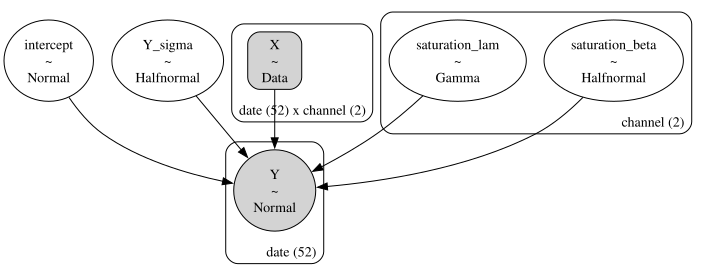

In [28]:
additive_gam.build_model(train)
pm.model_to_graphviz(additive_gam.model)

## 8. Look at the model before fitting

Prior predictive sampling simulates parameters from their priors.
It then simulates `Y` with these parameters and input `X`.
It does not use the observed `Y` to change the parameters.

In [29]:
prior = additive_gam.sample_prior_predictive(train, random_seed=42)

Sampling: [Y, Y_sigma, intercept, saturation_beta, saturation_lam]


Show the returned ArviZ object.
This version of ArviZ uses an `xarray.DataTree` with three groups:

- `prior` contains parameter samples and named terms.
- `prior_predictive` contains simulated responses.
- `observed_data` contains the supplied observations.

In [30]:
prior

<xarray.DataTree>
Group: /
├── Group: /prior
│       Dimensions:          (chain: 1, draw: 500, channel: 2)
│       Coordinates:
│         * chain            (chain) int64 8B 0
│         * draw             (draw) int64 4kB 0 1 2 3 4 5 6 ... 494 495 496 497 498 499
│         * channel          (channel) <U6 48B 'tv' 'search'
│       Data variables:
│           Y_sigma          (chain, draw) float64 4kB 0.2009 2.92 3.163 ... 0.656 1.833
│           intercept        (chain, draw) float64 4kB -1.649 1.406 ... -0.4846 0.6711
│           saturation_beta  (chain, draw, channel) float64 8kB 2.509 1.213 ... 1.139
│           saturation_lam   (chain, draw, channel) float64 8kB 3.41 2.714 ... 2.718
│       Attributes:
│           created_at:                 2026-10-16T22:21:46.597896+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
├── Group: /prior_predictive
│       Dimensions:  (chain: 1, draw: 500, date: 52)
│       Coordinates:
│         * chain    (chain) int64 8B 0
│         * draw     (draw) int64 4kB 0 1 2 3 4 5 6 7 ... 493 494 495 496 497 498 499
│         * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
│       Data variables:
│           Y        (chain, draw, date) float64 208kB 1.103 1.166 ... 1.04 0.986
│       Attributes:
│           created_at:                 2026-10-16T22:21:46.599082+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
└── Group: /observed_data
        Dimensions:  (date: 52)
        Coordinates:
          * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
        Data variables:
            Y        (date) float64 416B 1.65 2.026 1.172 1.954 ... 1.2 1.856 1.492
        Attributes:
            created_at:                 2026-10-16T22:21:46.599549+00:00
            creation_library:           ArviZ
            creation_library_version:   1.2.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.2
            sample_dims:                []

Open the `prior` group.
The intercept has dimensions `chain` and `draw`.
The saturation parameters also have dimension `channel`.

In [31]:
prior["prior"]

<xarray.DataTree 'prior'>
Group: /prior
    Dimensions:          (chain: 1, draw: 500, channel: 2)
    Coordinates:
      * chain            (chain) int64 8B 0
      * draw             (draw) int64 4kB 0 1 2 3 4 5 6 ... 494 495 496 497 498 499
      * channel          (channel) <U6 48B 'tv' 'search'
    Data variables:
        Y_sigma          (chain, draw) float64 4kB 0.2009 2.92 3.163 ... 0.656 1.833
        intercept        (chain, draw) float64 4kB -1.649 1.406 ... -0.4846 0.6711
        saturation_beta  (chain, draw, channel) float64 8kB 2.509 1.213 ... 1.139
        saturation_lam   (chain, draw, channel) float64 8kB 3.41 2.714 ... 2.718
    Attributes:
        created_at:                 2026-10-16T22:21:46.597896+00:00
        creation_library:           ArviZ
        creation_library_version:   1.2.0
        creation_library_language:  Python
        inference_library:          pymc
        inference_library_version:  6.3.2
        sample_dims:                ['chain', 'draw']

Compare simulated and observed response distributions.
Set `group="prior_predictive"` because these predictions come before fitting.

/Users/carlostrujillo/Documents/GitHub/_worktrees/pymc-marketing/agent-2963-experimental-mmm-notebook-review/.venv/lib/python3.13/site-packages/arviz_plots/plots/utils_ppc.py:68: UserWarning: This plot always uses the `observed_data` group.
Be cautious when using it for prior predictive checks.
  warn_if_prior_predictive(group)


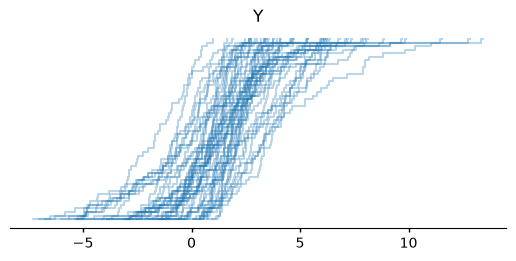

In [32]:
import arviz_plots as azp

azp.plot_ppc_dist(prior, group="prior_predictive", var_names=["Y"]);

The Normal likelihood can give negative responses.
The noise prior includes large values on this scale.
Use the predictions to compare the model with the observed response.
An added term does not select these settings for you.

## 9. Multiply the additive response by a price term

Terms can multiply other terms.
Multiply the whole additive response by a linear price factor:

```text
Y ~ (intercept + media.sum("channel")) * (price_raw * coef)
```

Add one price per date.
Keep the simulated observations.
These prices show model construction, not recovery of a known price effect.

In [33]:
priced_train = train.assign(price_raw=("date", np.linspace(8, 12, train.sizes["date"])))
priced_train

<xarray.Dataset> Size: 2kB
Dimensions:    (date: 52, channel: 2)
Coordinates:
  * date       (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
  * channel    (channel) <U6 48B 'tv' 'search'
Data variables:
    X          (date, channel) float64 832B 0.774 0.4389 ... 0.2659 0.9692
    Y          (date) float64 416B 1.65 2.026 1.172 1.954 ... 1.2 1.856 1.492
    price_raw  (date) float64 416B 8.0 8.078 8.157 8.235 ... 11.84 11.92 12.0

`Data("price_raw")` reads the new variable.
Use a scalar coefficient near 0.1 for prices near 10.
This makes the multiplier close to one.
The units and prior are choices, not automatic scaling.

In [34]:
price_raw = Data("price_raw")
coef = Parameter("price_coef", prior=Prior("Normal", mu=0.1, sigma=0.02))

Use `+` and `*` to connect the terms.
The price factor multiplies the baseline and media response.

In [35]:
media = X >> saturation
semi_mu = (intercept + media.sum("channel")) * (price_raw * coef)
semi_gam = GAM(Equation(observed="Y", mu=semi_mu))

Build a separate model.
Then show its graph.
The price data vary by date.
The scalar coefficient is shared across dates.

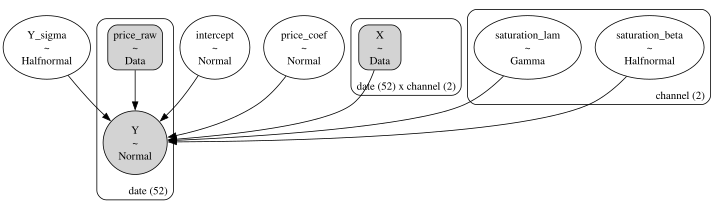

In [36]:
semi_gam.build_model(priced_train)
graph = pm.model_to_graphviz(semi_gam.model)
graph.graph_attr["size"] = "10,5"
graph

Use the same prior predictive method.
The `prior` group also contains `price_coef`.

In [37]:
semi_prior = semi_gam.sample_prior_predictive(priced_train, random_seed=43)
semi_prior

Sampling: [Y, Y_sigma, intercept, price_coef, saturation_beta, saturation_lam]


<xarray.DataTree>
Group: /
├── Group: /prior
│       Dimensions:          (chain: 1, draw: 500, channel: 2)
│       Coordinates:
│         * chain            (chain) int64 8B 0
│         * draw             (draw) int64 4kB 0 1 2 3 4 5 6 ... 494 495 496 497 498 499
│         * channel          (channel) <U6 48B 'tv' 'search'
│       Data variables:
│           Y_sigma          (chain, draw) float64 4kB 1.172 0.1612 ... 2.924 0.8619
│           intercept        (chain, draw) float64 4kB 0.2014 0.0008091 ... -1.216 1.904
│           saturation_beta  (chain, draw, channel) float64 8kB 1.259 1.874 ... 4.801
│           saturation_lam   (chain, draw, channel) float64 8kB 2.538 3.853 ... 4.738
│           price_coef       (chain, draw) float64 4kB 0.1033 0.09638 ... 0.1286 0.07197
│       Attributes:
│           created_at:                 2026-10-16T22:21:47.271546+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
├── Group: /prior_predictive
│       Dimensions:  (chain: 1, draw: 500, date: 52)
│       Coordinates:
│         * chain    (chain) int64 8B 0
│         * draw     (draw) int64 4kB 0 1 2 3 4 5 6 7 ... 493 494 495 496 497 498 499
│         * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
│       Data variables:
│           Y        (chain, draw, date) float64 208kB 1.583 1.239 1.047 ... 7.482 7.161
│       Attributes:
│           created_at:                 2026-10-16T22:21:47.272955+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
└── Group: /observed_data
        Dimensions:  (date: 52)
        Coordinates:
          * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
        Data variables:
            Y        (date) float64 416B 1.65 2.026 1.172 1.954 ... 1.2 1.856 1.492
        Attributes:
            created_at:                 2026-10-16T22:21:47.273426+00:00
            creation_library:           ArviZ
            creation_library_version:   1.2.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.2
            sample_dims:                []

The price factor is `price_raw * coef`.
It has no power, reference price, or added intercept.
At zero price, the conditional mean is zero.
The model keeps Normal observation noise.
This coefficient is not a price elasticity.
This example does not fit a price-demand model.

## 10. Two outcomes, shared media inputs

Add install responses for Android and iOS.
Put the two series in `Y` with dimensions `date` and `os`.
This is one observed variable and one equation.

Keep `X` with dimensions `date` and `channel`.
Keep the date-level price.
Then add the OS labels.

In [38]:
os_train = priced_train.drop_vars("Y").assign_coords(os=["Android", "iOS"])

Add special advertising `Z` for each date and OS.
This input has no `channel` dimension.

In [39]:
os_train["Z"] = (
    ("date", "os"),
    rng.uniform(0, 1, size=(train.sizes["date"], 2)),
)

Simulate example install counts.
Then divide them by 100.
These observations show the data structure, not a known advertising effect.
Keep the Normal likelihood for this scaled response.

In [40]:
os_train["Y"] = (
    ("date", "os"),
    rng.poisson([100, 150], size=(train.sizes["date"], 2)) / 100,
)
os_train

<xarray.Dataset> Size: 3kB
Dimensions:    (date: 52, channel: 2, os: 2)
Coordinates:
  * date       (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
  * channel    (channel) <U6 48B 'tv' 'search'
  * os         (os) <U7 56B 'Android' 'iOS'
Data variables:
    X          (date, channel) float64 832B 0.774 0.4389 ... 0.2659 0.9692
    price_raw  (date) float64 416B 8.0 8.078 8.157 8.235 ... 11.84 11.92 12.0
    Z          (date, os) float64 832B 0.1536 0.1155 0.02115 ... 0.8984 0.7625
    Y          (date, os) float64 832B 0.93 1.43 0.98 1.59 ... 1.33 0.98 1.59

### Regular channels: parameters by channel and OS

Set the dimensions of the two saturation parameters to `("channel", "os")`.
The same spend input can then give different Android and iOS responses.
No copy of `X` across OS is necessary.

In [41]:
x_saturation = LogisticSaturation(prefix="x_saturation").with_default_prior_dims(
    ("channel", "os")
)
x_media = X >> x_saturation

### Special advertising: parameters by OS only

Give `Z` saturation parameters with only dimension `os`.
Use separate prefixes to keep the two parameter sets distinct.

In [42]:
z_saturation = LogisticSaturation(prefix="z_saturation").with_default_prior_dims(
    ("os",)
)
z_media = Data("Z") >> z_saturation

Give each OS its own baseline.

In [43]:
base_os = Parameter("base_os", prior=Prior("Normal", mu=0, sigma=1, dims="os"))

### Price: one fully pooled coefficient

Set `dims=()` for one price coefficient shared by the two OS outcomes.
The price input varies by date.
Pooling the coefficient does not make the input constant.

In [44]:
pooled_price_coef = Parameter(
    "price_coef", prior=Prior("Normal", mu=0.1, sigma=0.02, dims=())
)

Connect the terms with the same multiplication rule.
Sum only the regular channels in `X`.
`Z` already has one response per date and OS.
Keep `os` in the output.

In [45]:
os_mu = (base_os + x_media.sum("channel") + z_media) * (price_raw * pooled_price_coef)
os_gam = GAM(Equation(observed="Y", mu=os_mu))

Build the model.
Then show its parameter dimensions.
The likelihood uses dimensions `date` and `os` from `os_train["Y"]`.
The noise parameter stays scalar.

In [46]:
os_gam.build_model(os_train)
model_table(os_gam.model)

            Variable  Expression                                                             Dimensions            
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
                 X =  Data                                                                   date[52] × channel[2] 
                 Z =  Data                                                                   date[52] × os[2]      
         price_raw =  Data                                                                   date[52]              
                                                                                                                   
           base_os ~  Normal(0, 1)                                                           os[2]                 
  x_saturation_lam ~  Gamma(3, <constant>)                                                   channel[2] × os[2]    
 x_saturation_beta ~  HalfNormal(0, 2)                                                       channel[2] × os[2]    
  z_saturation_lam ~  Gamma(3, <constant>)                                                   os[2]                 
 z_saturation_beta ~  HalfNormal(0, 2)                                                       os[2]                 
        price_coef ~  Normal(0.1, 0.02)                                                                            
           Y_sigma ~  HalfNormal(0, 2)                                                                             
                                                                                             Parameter count = 16  
                                                                                                                   
                 Y ~  Unknown(Normal(f(price_coef, z_saturation_beta, base_os,               date[52] × os[2]      
                      x_saturation_beta, z_saturation_lam, x_saturation_lam), Y_sigma))

The table can show `Unknown(...)` around the Normal likelihood.
This is a PyMC printing limitation, not a different likelihood.
Graphviz shows the dimension reorder as `Transpose`.
The notation `f(...)` represents the combined mean.

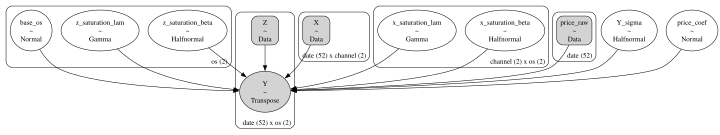

In [47]:
os_graph = pm.model_to_graphviz(os_gam.model)
os_graph.graph_attr["size"] = "10,7"
os_graph

Sample prior predictions.
The `prior` group contains channel-by-OS, OS-only, and scalar parameters.
The simulated `Y` has dimensions `chain`, `draw`, `date`, and `os`.

In [48]:
os_prior = os_gam.sample_prior_predictive(os_train, random_seed=44)
os_prior

Sampling: [Y, Y_sigma, base_os, price_coef, x_saturation_beta, x_saturation_lam, z_saturation_beta, z_saturation_lam]


<xarray.DataTree>
Group: /
├── Group: /prior
│       Dimensions:            (chain: 1, draw: 500, channel: 2, os: 2)
│       Coordinates:
│         * chain              (chain) int64 8B 0
│         * draw               (draw) int64 4kB 0 1 2 3 4 5 ... 494 495 496 497 498 499
│         * channel            (channel) <U6 48B 'tv' 'search'
│         * os                 (os) <U7 56B 'Android' 'iOS'
│       Data variables:
│           x_saturation_lam   (chain, draw, channel, os) float64 16kB 0.8944 ... 2.669
│           Y_sigma            (chain, draw) float64 4kB 0.8848 0.5266 ... 1.568 0.4075
│           x_saturation_beta  (chain, draw, channel, os) float64 16kB 1.065 ... 0.2784
│           z_saturation_beta  (chain, draw, os) float64 8kB 1.138 0.2073 ... 1.96 3.118
│           base_os            (chain, draw, os) float64 8kB 0.55 0.562 ... 0.5171
│           z_saturation_lam   (chain, draw, os) float64 8kB 4.593 5.332 ... 1.254
│           price_coef         (chain, draw) float64 4kB 0.1608 0.101 ... 0.09718
│       Attributes:
│           created_at:                 2026-10-16T22:21:47.534895+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
├── Group: /prior_predictive
│       Dimensions:  (chain: 1, draw: 500, date: 52, os: 2)
│       Coordinates:
│         * chain    (chain) int64 8B 0
│         * draw     (draw) int64 4kB 0 1 2 3 4 5 6 7 ... 493 494 495 496 497 498 499
│         * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
│         * os       (os) <U7 56B 'Android' 'iOS'
│       Data variables:
│           Y        (chain, draw, date, os) float64 416kB 3.338 3.555 ... 4.333 3.31
│       Attributes:
│           created_at:                 2026-10-16T22:21:47.536491+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.2
│           sample_dims:                ['chain', 'draw']
└── Group: /observed_data
        Dimensions:  (date: 52, os: 2)
        Coordinates:
          * date     (date) datetime64[us] 416B 2025-01-06 2025-01-13 ... 2025-12-29
          * os       (os) <U7 56B 'Android' 'iOS'
        Data variables:
            Y        (date, os) float64 832B 0.93 1.43 0.98 1.59 ... 1.03 1.33 0.98 1.59
        Attributes:
            created_at:                 2026-10-16T22:21:47.537028+00:00
            creation_library:           ArviZ
            creation_library_version:   1.2.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.2
            sample_dims:                []

Inputs can have different dimensions in one model.
Labels and parameter dimensions control which effects vary by OS.
The explicit sum removes only `channel`.
The linear price factor multiplies the whole additive mean.

## Next steps

The [main MMM example](experimental_mmm_api.ipynb) adds fitting, forecasts, and budget optimization.
The [semi-multiplicative example](semi_multiplicative_demo_terms.ipynb) fits a power price factor.

In [49]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor

Last updated: Sat, 17 Oct 2026

Python implementation: CPython
Python version       : 3.13.9
IPython version      : 9.15.0

pymc_marketing: 1.2.0
pytensor      : 3.3.2

arviz_plots   : 1.2.0
numpy         : 2.4.6
pandas        : 3.0.5
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
xarray        : 2026.4.0

Watermark: 2.6.0

